# Three launch readouts: analysis notebook

Builds the dbt project (models and data tests) on the synthetic data, then draws the charts used in the README. Run `python data/generate.py` first.

In [1]:
import json
import duckdb
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
from run_analysis import build, feed_intervals, badge_intervals, ab_readout, DB

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
IMG = Path('images'); IMG.mkdir(exist_ok=True)
BLUE, GREY, ORANGE, RED = '#2f6f8f', '#9a9a9a', '#e3a33b', '#d1495b'
build()
con = duckdb.connect(DB, read_only=True)
truth = json.load(open('data/raw/planted_effects.json'))

## 1. Home feed redesign

Every September sessions go up, launch or not. Drawing 2025 on top of 2024 shows how much of the jump is the calendar.

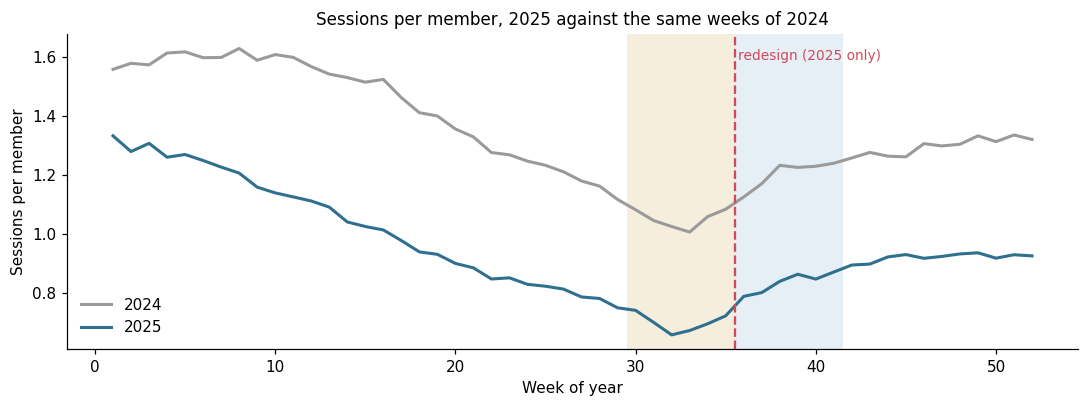

In [2]:
tr = con.table('feed_weekly_trend').df()
fig, ax = plt.subplots(figsize=(10, 3.8))
for year, color in [(2024, GREY), (2025, BLUE)]:
    s = tr[tr.year == year].sort_values('week_of_year')
    ax.plot(s.week_of_year, s.sessions_per_member, color=color, lw=2, label=str(year))
launch_wk = pd.Timestamp('2025-09-01').isocalendar()[1]
ax.axvspan(launch_wk - 6.5, launch_wk - 0.5, color='#f1e3c6', alpha=0.6, lw=0)
ax.axvspan(launch_wk - 0.5, launch_wk + 5.5, color='#dbe9f1', alpha=0.7, lw=0)
ax.axvline(launch_wk - 0.5, color=RED, ls='--')
ax.text(launch_wk - 0.3, ax.get_ylim()[1] * 0.97, 'redesign (2025 only)', color=RED, fontsize=9, va='top')
ax.set_xlabel('Week of year'); ax.set_ylabel('Sessions per member')
ax.set_title('Sessions per member, 2025 against the same weeks of 2024', fontsize=11)
ax.legend(frameon=False, loc='lower left')
fig.tight_layout(); fig.savefig(IMG / 'feed_seasonality.png', bbox_inches='tight')

,scenario,metric,before_value,after_value,change_this_year,change_prior_year,change_adjusted
0,launch,partner_views_per_session,0.564,0.315,-0.442,-0.013,-0.435
1,launch,sessions_per_member_week,0.700,0.837,0.195,0.146,0.043
2,launch,workouts_per_member_week,0.441,0.501,0.134,0.147,-0.011
3,placebo,partner_views_per_session,0.344,0.701,1.038,-0.363,2.197
4,placebo,sessions_per_member_week,0.915,0.816,-0.109,-0.113,0.005
5,placebo,workouts_per_member_week,0.579,0.516,-0.109,-0.118,0.010


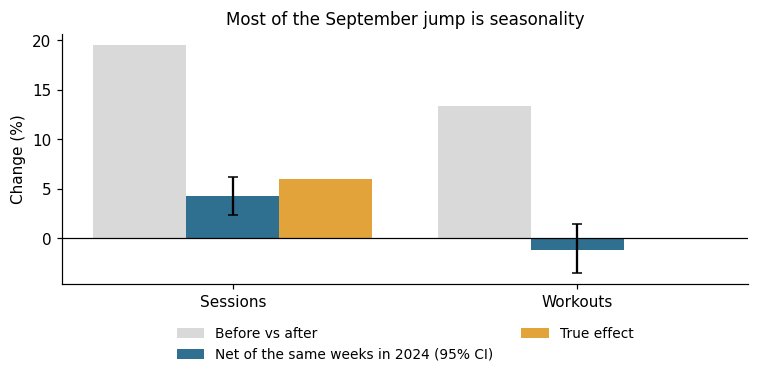

In [3]:
est = con.table('feed_estimates').df()
launch = est[est.scenario == 'launch'].set_index('metric')
ci = feed_intervals(con, 'launch')
labels = {'sessions_per_member_week': 'Sessions', 'workouts_per_member_week': 'Workouts'}
true = {'sessions_per_member_week': truth['feed_sessions'], 'workouts_per_member_week': truth['feed_workouts']}
fig, ax = plt.subplots(figsize=(7, 3.6))
x = range(len(labels))
naive = [launch.loc[m, 'change_this_year'] * 100 for m in labels]
adj = [launch.loc[m, 'change_adjusted'] * 100 for m in labels]
err = [[a - ci[m][0] * 100 for a, m in zip(adj, labels)], [ci[m][1] * 100 - a for a, m in zip(adj, labels)]]
ax.bar([i - 0.27 for i in x], naive, 0.27, color='#d9d9d9', label='Before vs after')
ax.bar(list(x), adj, 0.27, color=BLUE, yerr=err, capsize=3, label='Net of the same weeks in 2024 (95% CI)')
ax.bar([i + 0.27 for i in x], [true[m] * 100 for m in labels], 0.27, color=ORANGE, label='True effect')
ax.axhline(0, color='black', lw=0.8)
ax.set_xticks(list(x)); ax.set_xticklabels(labels.values()); ax.set_ylabel('Change (%)')
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=9)
ax.set_title('Most of the September jump is seasonality', fontsize=11)
fig.tight_layout(); fig.savefig(IMG / 'feed_naive_vs_adjusted.png', bbox_inches='tight')
est.round(3)

Partner challenge views per session fell 44% after launch. The weekly series shows the drop started in July, when a sponsored campaign peaked and wound down. A one-year comparison does not fix this: campaigns fall on different weeks each year, which is why the placebo date finds a huge fake effect for this metric.

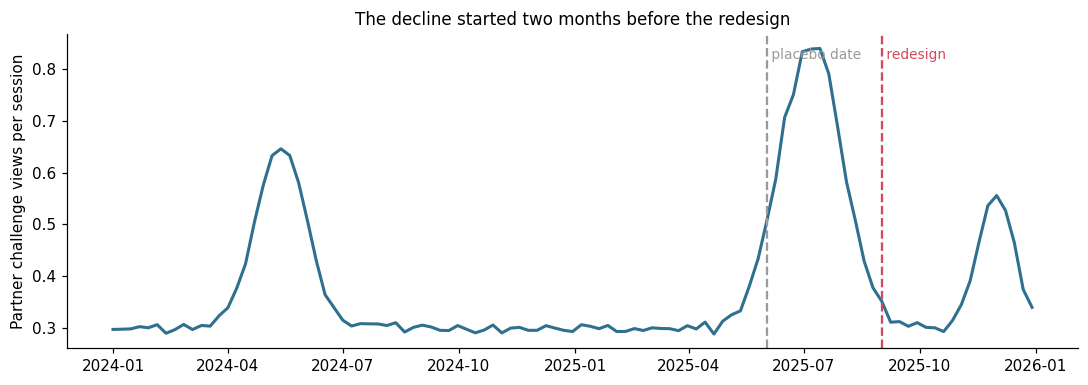

In [4]:
tr['week_start'] = pd.to_datetime(tr['week_start'])
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(tr.week_start, tr.partner_views_per_session, color=BLUE, lw=2)
for d, name, color in [('2025-09-01', 'redesign', RED), ('2025-06-02', 'placebo date', GREY)]:
    ax.axvline(pd.Timestamp(d), color=color, ls='--')
    ax.text(pd.Timestamp(d), ax.get_ylim()[1] * 0.97, f' {name}', fontsize=9, va='top', color=color)
ax.set_ylabel('Partner challenge views per session')
ax.set_title('The decline started two months before the redesign', fontsize=11)
fig.tight_layout(); fig.savefig(IMG / 'partner_views_trend.png', bbox_inches='tight')

## 2. Century badge

Holders give far more kudos than non-holders after launch. They also did before badges existed.

,award_type,holders,share_of_holders
0,backfill,4861,0.902525
1,organic,525,0.097475


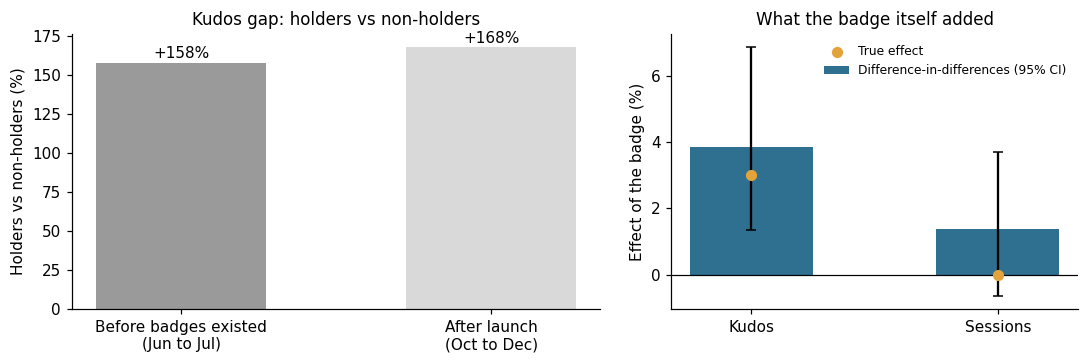

In [5]:
b = con.table('badge_estimates').df().set_index('metric')
bci = badge_intervals(con)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={'width_ratios': [1.3, 1]})
ax = axes[0]
gaps = [b.loc['kudos', 'gap_before_launch'], b.loc['kudos', 'gap_after_launch']]
ax.bar([0, 1], [g * 100 for g in gaps], color=[GREY, '#d9d9d9'], width=0.55)
ax.set_xticks([0, 1]); ax.set_xticklabels(['Before badges existed\n(Jun to Jul)', 'After launch\n(Oct to Dec)'])
ax.set_ylabel('Holders vs non-holders (%)'); ax.set_title('Kudos gap: holders vs non-holders', fontsize=11)
for i, v in enumerate(gaps):
    ax.text(i, v * 100 + 3, f'+{v:.0%}', ha='center', fontsize=10)
ax = axes[1]
vals = [b.loc['kudos', 'did_relative'] * 100, b.loc['sessions', 'did_relative'] * 100]
lo = [bci['kudos_per_week'][0] * 100, bci['sessions_per_week'][0] * 100]
hi = [bci['kudos_per_week'][1] * 100, bci['sessions_per_week'][1] * 100]
ax.bar([0, 1], vals, color=BLUE, width=0.5, yerr=[[v - l for v, l in zip(vals, lo)], [h - v for v, h in zip(vals, hi)]],
       capsize=3, label='Difference-in-differences (95% CI)')
ax.scatter([0, 1], [truth['badge_kudos'] * 100, 0], color=ORANGE, zorder=3, s=40, label='True effect')
ax.axhline(0, color='black', lw=0.8)
ax.set_xticks([0, 1]); ax.set_xticklabels(['Kudos', 'Sessions']); ax.set_ylabel('Effect of the badge (%)')
ax.set_title('What the badge itself added', fontsize=11); ax.legend(frameon=False, fontsize=8, loc='upper right')
fig.tight_layout(); fig.savefig(IMG / 'badge_selection.png', bbox_inches='tight')
con.table('badge_award_mix').df()

## 3. Onboarding email A/B test

Split 5,970 / 6,030, sample ratio check p = 0.58, planned MDE 2.3 pp


,metric,control,new_email,diff_pp,ci_low_pp,ci_high_pp,p_value
0,first_workout_7d,0.2961,0.3322,3.6025,1.9428,5.2622,0.0000
1,active_day_30,0.2831,0.2881,0.4978,-1.1185,2.1141,0.5461


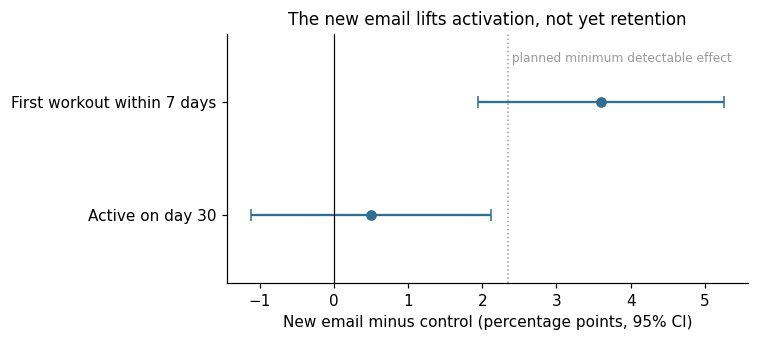

In [6]:
ab, n_c, n_t, srm_p, mde = ab_readout(con)
fig, ax = plt.subplots(figsize=(7, 3.2))
names = {'first_workout_7d': 'First workout within 7 days', 'active_day_30': 'Active on day 30'}
y = list(range(len(ab)))[::-1]
ax.errorbar(ab.diff_pp, y, xerr=[ab.diff_pp - ab.ci_low_pp, ab.ci_high_pp - ab.diff_pp], fmt='o', color=BLUE, capsize=4)
ax.axvline(0, color='black', lw=0.8)
ax.axvline(mde * 100, color=GREY, ls=':', lw=1)
ax.text(mde * 100, max(y) + 0.35, ' planned minimum detectable effect', fontsize=8, color=GREY)
ax.set_yticks(y); ax.set_yticklabels([names[m] for m in ab.metric]); ax.set_ylim(-0.6, max(y) + 0.6)
ax.set_xlabel('New email minus control (percentage points, 95% CI)')
ax.set_title('The new email lifts activation, not yet retention', fontsize=11)
fig.tight_layout(); fig.savefig(IMG / 'email_ab_test.png', bbox_inches='tight')
print(f'Split {n_c:,} / {n_t:,}, sample ratio check p = {srm_p:.2f}, planned MDE {mde * 100:.1f} pp')
ab.round(4)